In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import time

In [38]:
L = 32                                    # panjang sisi lattice persegi 2D
N = L * L                                 # jumlah spin
J = 1.0                                   # kuat interaksi
D = np.sqrt(2) * np.tan(np.pi/4)          # kuat DMI

B_z = 1                                   # medan arah z; coba juga 0.5 (satuan J/mu)

q0 = np.pi / 4
J2 = J / (2 * np.cos(q0))

n_therm = 2000
n_measure = 5000

sigma_initial = 60.0
T = np.linspace(5, 0.01, 50) 
total_start = time.perf_counter()

In [39]:
def random_spin_field():
    spins = np.random.normal(size=(L, L, 3))
    spins /= np.linalg.norm(spins, axis=2, keepdims=True)
    return spins

lattice = random_spin_field()
print(lattice.shape)


(32, 32, 3)


In [40]:
def delta_energy_dmi(lattice, x, y, trial_spin, B_z):
    L = lattice.shape[0]
    nn = lattice[(x + 1) % L, y] + lattice[(x - 1) % L, y] + lattice[x, (y + 1) % L] + lattice[x, (y - 1) % L]
    old_spin = lattice[x, y]
    E_exchange = -J * np.dot(trial_spin - old_spin, nn)
    E_dmi = -D * (np.dot(trial_spin - old_spin, np.cross(lattice[(x + 1) % L, y] - lattice[(x - 1) % L, y], [1, 0, 0])) + np.dot(trial_spin - old_spin, np.cross(lattice[x, (y + 1) % L] - lattice[x, (y - 1) % L], [0, 1, 0])))
    E_field = -B_z * (trial_spin[2] - old_spin[2])
    return E_exchange + E_dmi + E_field 

In [41]:
def delta_energy_frustration(lattice, x, y,trial_spin, B_z):
    L = lattice.shape[0]
    nn = lattice[(x + 1) % L, y] + lattice[(x - 1) % L, y]  + lattice[x, (y + 1) % L] + lattice[x, (y - 1) % L]
    nnn = lattice[(x + 2) % L, y] + lattice[(x - 2) % L, y]
    old_spin = lattice[x, y]
    E_exchange = -J * np.dot(trial_spin - old_spin, nn)
    E_frustration = J2 * np.dot(trial_spin - old_spin, nnn)
    E_field = -B_z * (trial_spin[2] - old_spin[2])
    return E_exchange + E_frustration + E_field

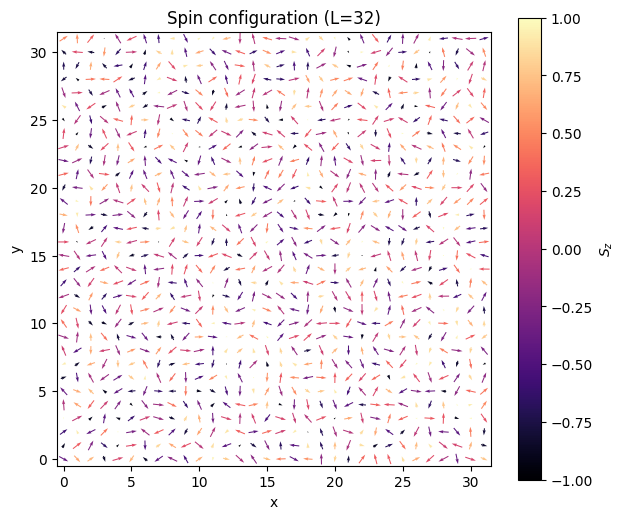

In [42]:
L = lattice.shape[0]


Sx = lattice[:, :, 0].T
Sy = lattice[:, :, 1].T
Sz = lattice[:, :, 2].T

X, Y = np.meshgrid(np.arange(L), np.arange(L))
fig, ax = plt.subplots(figsize=(7, 6))
norm = Normalize(vmin=-1, vmax=1)
cmap = plt.get_cmap("magma")

q = ax.quiver(X, Y, Sx, Sy, Sz, cmap=cmap, norm=norm, pivot="middle", scale_units="xy", scale=1.2)

fig.colorbar(q, ax=ax, label=r"$S_z$")

ax.set_xlim(-0.5, L - 0.5)
ax.set_ylim(-0.5, L - 0.5)
ax.set_aspect("equal")

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"Spin configuration (L={L})")

plt.show()

In [43]:
def magnetization(lattice):
    return np.sum(lattice, axis=(0, 1))

$$
\mathbf{S}_i^{\mathrm{baru}}
=
\frac{
\mathbf{S}_i^{\mathrm{lama}}
+
\sigma\mathbf{\Gamma}
}{
\left|
\mathbf{S}_i^{\mathrm{lama}}
+
\sigma\mathbf{\Gamma}
\right|
}
$$

Jika jumlah trial move yang diterima adalah $N_{\mathrm{accepted}}$, maka acceptance rate adalah

$$
R
=
\frac{N_{\mathrm{accepted}}}{N}
$$

$$
f
=
\frac{0.5}{1-R}
$$

$$
\sigma_{\mathrm{baru}}
=
\sigma_{\mathrm{lama}}
\frac{0.5}{1-R}
$$


In [44]:
def total_energy_dmi(lattice, B_z):
    nx, ny = lattice.shape[:2]
    E = 0.0

    for x in range(nx):
        for y in range(ny):
            E += -J * np.dot(lattice[x, y], lattice[(x + 1) % nx, y] + lattice[x, (y + 1) % ny])
            E += D * (np.dot(lattice[x, y], np.cross([1, 0, 0], lattice[(x + 1) % nx, y])) + np.dot(lattice[x, y], np.cross([0, 1, 0], lattice[x, (y + 1) % ny])))
            E -= B_z * lattice[x, y, 2]

    return E


def total_energy_frustration(lattice, B_z):
    nx, ny = lattice.shape[:2]
    E = 0.0

    for x in range(nx):
        for y in range(ny):
            nn = lattice[(x + 1) % nx, y] + lattice[x, (y + 1) % ny]
            nnn = lattice[(x + 2) % nx, y]

            E += -J * np.dot(lattice[x, y], nn)
            E += J2 * np.dot(lattice[x, y], nnn)
            E -= B_z * lattice[x, y, 2]

    return E


In [45]:
def gaussian_trial(spin, sigma):
    gamma = np.random.normal(size=3)
    trial = spin + sigma * gamma
    norm = np.linalg.norm(trial)

    if norm == 0.0:
        return spin.copy()

    return trial / norm

def metropolis_step(lattice, T, sigma, B_z, model):
    nx, ny = lattice.shape[:2]
    x = np.random.randint(0, nx)
    y = np.random.randint(0, ny)

    trial_spin = gaussian_trial(lattice[x, y], sigma)

    if model == "dmi": dE = delta_energy_dmi(lattice, x, y, trial_spin, B_z)
    if model == "frustration": dE = delta_energy_frustration(lattice, x, y, trial_spin, B_z)

    if dE <= 0 or np.random.random() < np.exp(-dE / T):
        lattice[x, y] = trial_spin
        return 1

    return 0

def update_sigma(sigma, R):
    if R >= 1.0:
        return 60.0

    sigma = sigma * (0.5 / (1.0 - R))
    sigma = min(sigma, 60.0)
    sigma = max(sigma, 1e-8)
    return sigma


In [46]:
def simulate(lattice, temp, B_z, model):
    energies = []
    magnetizations = []
    R_history = []
    sigma_history = []

    sigma = sigma_initial

    for sweep in range(n_therm + n_measure):
        accepted = 0

        for i in range(N):
            accepted += metropolis_step(lattice, temp, sigma, B_z, model)

        R = accepted / N
        if sweep < n_therm:
            sigma = update_sigma(sigma, R)

        R_history.append(R)
        sigma_history.append(sigma)

        if sweep >= n_therm:
            if model == "dmi":
                energies.append(total_energy_dmi(lattice, B_z))
            if model == "frustration":
                energies.append(total_energy_frustration(lattice, B_z))

            magnetizations.append(magnetization(lattice))

    return (
        np.array(energies),
        np.array(magnetizations),
        np.array(R_history),
        np.array(sigma_history),
    )

In [ ]:
def simulate_temp(lattice, T, B_z, model):
    c_vs_t = []
    kai_vs_t = []
    m_vs_t = []
    e_vs_t = []
    r_vs_t = []
    sigma_vs_t = []

    spins_t = lattice.copy()
    for t in T:
        start_time = time.time()

        energies, magnetizations, R_history, sigma_history = simulate(spins_t, t, B_z, model)

        E_mean = np.mean(energies)
        E_2_mean = np.mean(energies ** 2)

        M_abs = np.linalg.norm(magnetizations, axis=1)
        M_abs_mean = np.mean(M_abs)
        M_2_mean = np.mean(M_abs ** 2)

        c = (E_2_mean - E_mean ** 2) / (N * t ** 2)
        Kai = (M_2_mean - M_abs_mean ** 2) / (N * t)

        c_vs_t.append(c)
        kai_vs_t.append(Kai)
        m_vs_t.append(M_abs_mean / N)
        e_vs_t.append(E_mean / N)
        r_vs_t.append(np.mean(R_history[n_therm:]))
        sigma_vs_t.append(np.mean(sigma_history[n_therm:]))

        total_time = time.time() - start_time
        print(f"Temperature: {t:.4f}, Time taken: {total_time:.2f} seconds")
        print(f"Heat Capacity: {c:.4f}, Susceptibility: {Kai:.4f}, Magnetization: {M_abs_mean / N:.4f}, Energy: {E_mean / N:.4f}")
        print("-" * 50)

    return (
        np.array(c_vs_t),
        np.array(kai_vs_t),
        np.array(m_vs_t),
        np.array(e_vs_t),
        np.array(r_vs_t),
        np.array(sigma_vs_t),
    )


c_vs_t_dmi, kai_vs_t_dmi, m_vs_t_dmi, e_vs_t_dmi, r_vs_t_dmi, sigma_vs_t_dmi = simulate_temp(lattice, T, B_z, "dmi")
c_vs_t_frustration, kai_vs_t_frustration, m_vs_t_frustration, e_vs_t_frustration, r_vs_t_frustration, sigma_vs_t_frustration = simulate_temp(lattice, T, B_z, "frustration")

Temperature: 5.0000, Time taken: 392.13 seconds
Heat Capacity: 0.0879, Susceptibility: 0.0796, Magnetization: 0.0905, Energy: -0.4089
--------------------------------------------------
Temperature: 4.8982, Time taken: 386.83 seconds
Heat Capacity: 0.0885, Susceptibility: 0.0803, Magnetization: 0.0914, Energy: -0.4166
--------------------------------------------------
Temperature: 4.7963, Time taken: 383.47 seconds
Heat Capacity: 0.0963, Susceptibility: 0.0874, Magnetization: 0.0945, Energy: -0.4277
--------------------------------------------------
Temperature: 4.6945, Time taken: 384.26 seconds
Heat Capacity: 0.1016, Susceptibility: 0.0849, Magnetization: 0.0973, Energy: -0.4389
--------------------------------------------------
Temperature: 4.5927, Time taken: 383.18 seconds
Heat Capacity: 0.1082, Susceptibility: 0.0923, Magnetization: 0.0988, Energy: -0.4487
--------------------------------------------------
Temperature: 4.4908, Time taken: 384.09 seconds
Heat Capacity: 0.1096, Susc

In [ ]:
df_dmi = pd.DataFrame({
    "T": T,
    "c_vs_t_dmi": c_vs_t_dmi,
    "kai_vs_t_dmi": kai_vs_t_dmi,
    "m_vs_t_dmi": m_vs_t_dmi,
    "e_vs_t_dmi": e_vs_t_dmi,
    "r_vs_t_dmi": r_vs_t_dmi,
    "sigma_vs_t_dmi": sigma_vs_t_dmi,
})

df_frustration = pd.DataFrame({
    "T": T,
    "c_vs_t_frustration": c_vs_t_frustration,
    "kai_vs_t_frustration": kai_vs_t_frustration,
    "m_vs_t_frustration": m_vs_t_frustration,
    "e_vs_t_frustration": e_vs_t_frustration,
    "r_vs_t_frustration": r_vs_t_frustration,
    "sigma_vs_t_frustration": sigma_vs_t_frustration,
})

df_dmi.to_csv("dmi_Bz_results.csv", index=False)
df_frustration.to_csv("dmi_results.csv", index=False)

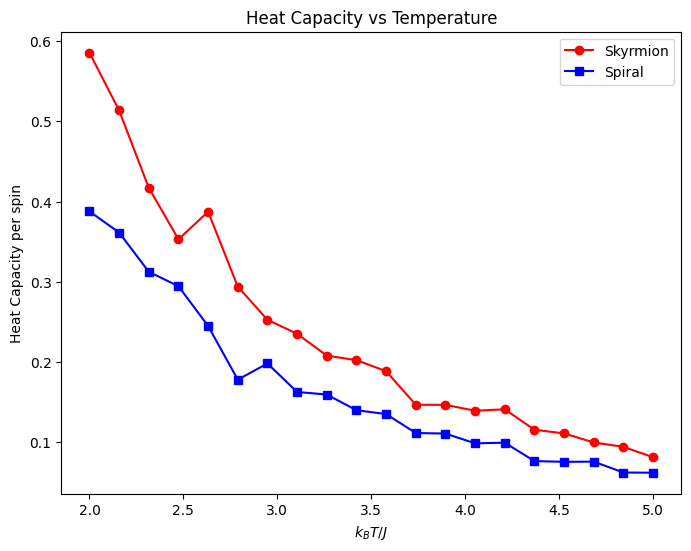

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(T, c_vs_t_dmi, marker="o", color="red", label="Skyrmion")
plt.plot(T, c_vs_t_frustration, marker="s", color="blue", label="Frustration")
plt.xlabel(r"$k_B T/J$")
plt.ylabel("Heat Capacity per spin")
plt.title("Heat Capacity vs Temperature")
plt.legend()
plt.show()

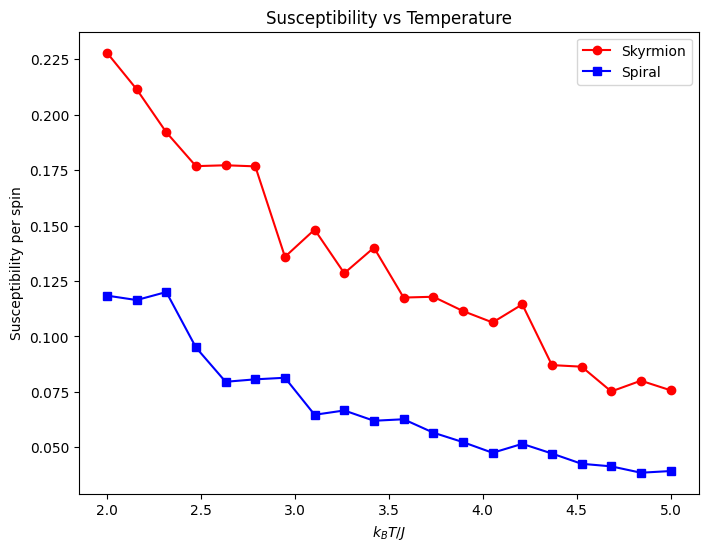

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(T, kai_vs_t_dmi, marker="o", color="red", label="Skyrmion")
plt.plot(T, kai_vs_t_frustration, marker="s", color="blue", label="Frustration")
plt.xlabel(r"$k_B T/J$")
plt.ylabel("Susceptibility per spin")
plt.title("Susceptibility vs Temperature")
plt.legend()
plt.show()

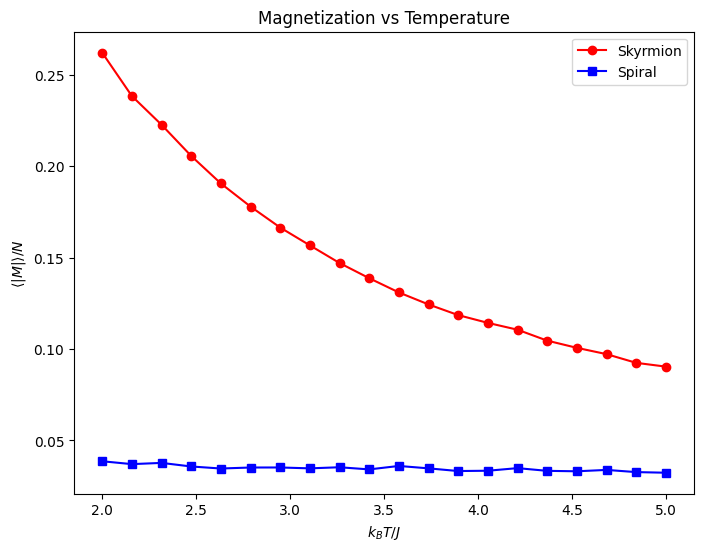

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(T, m_vs_t_dmi, marker="o", color="red", label="Skyrmion")
plt.plot(T, m_vs_t_frustration, marker="s", color="blue", label="Frustration")
plt.xlabel(r"$k_B T/J$")
plt.ylabel(r"$\langle |M| \rangle/N$")
plt.title("Magnetization vs Temperature")
plt.legend()
plt.show()

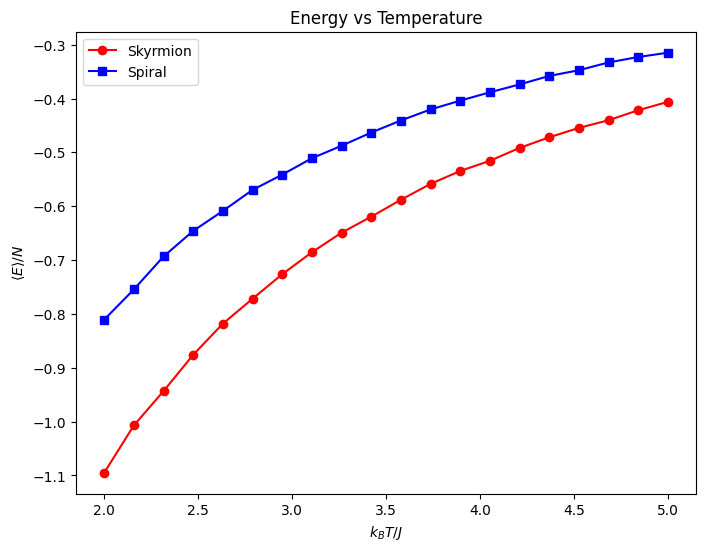

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(T, e_vs_t_dmi, marker="o", color="red", label="Skyrmion")
plt.plot(T, e_vs_t_frustration, marker="s", color="blue", label="Frustration")
plt.xlabel(r"$k_B T/J$")
plt.ylabel(r"$\langle E \rangle/N$")
plt.title("Energy vs Temperature")
plt.legend()
plt.show()

In [ ]:
total_time = time.perf_counter() - total_start
print(f"\nTotal simulation time: {total_time:.2f} s")


Total simulation time: 2523.15 s


In [ ]:
# final_lattice_spiral = lattice.copy()
# for i in T:
#     print(f"Simulating Spiral at T={i:.4f}")
#     temp = i
#     simulate(final_lattice_spiral, temp, 0)

#     spins = final_lattice_spiral

#     fig, ax = plt.subplots(figsize=(7, 6))
#     q = ax.quiver(
#         spins[:, :, 0].T,
#         spins[:, :, 1].T,
#         spins[:, :, 2].T,
#         cmap="magma",
#         norm=Normalize(vmin=-1, vmax=1),
#         pivot="middle",
#         scale_units="xy",
#         scale=1.2,
#     )

#     fig.colorbar(q, ax=ax, label=r"$S_z$")
#     ax.set_xlabel("x")
#     ax.set_ylabel("y")
#     ax.set_aspect("equal")
#     ax.set_title(f"Spiral Phase, T={temp:.3f}")
#     plt.show()

Simulating Spiral at T=5.0000


KeyboardInterrupt: 

Simulating at T=2.2000


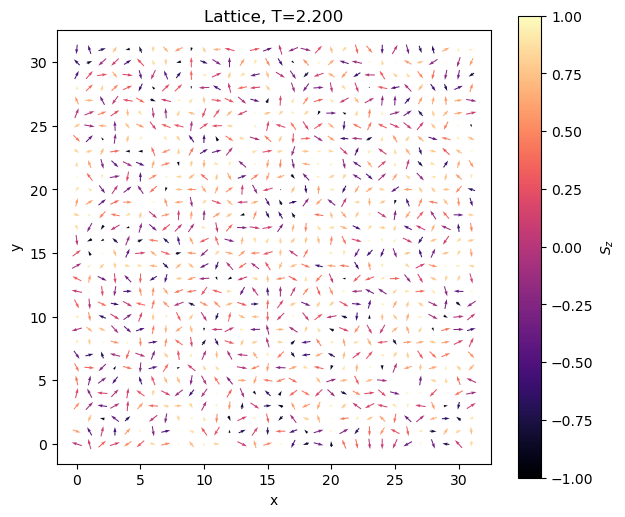

Simulating at T=2.1436


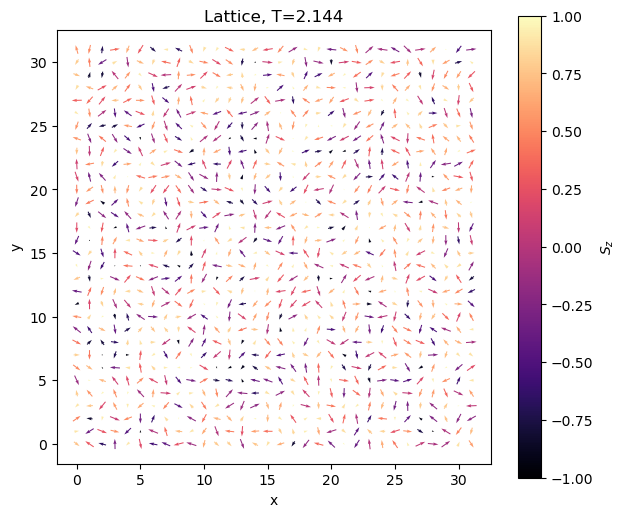

Simulating at T=2.0872


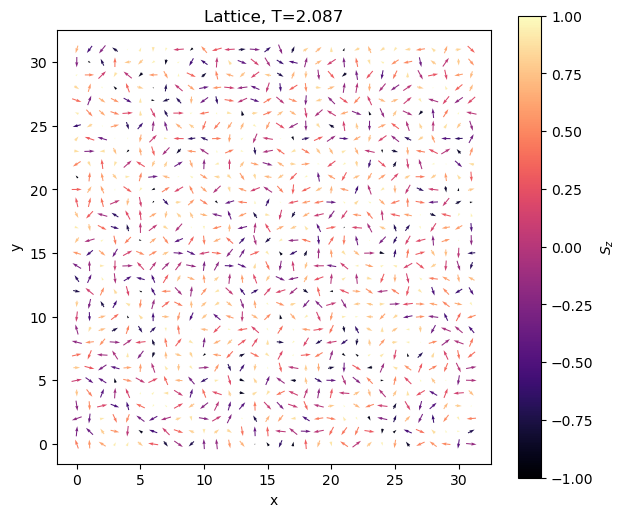

Simulating at T=2.0308


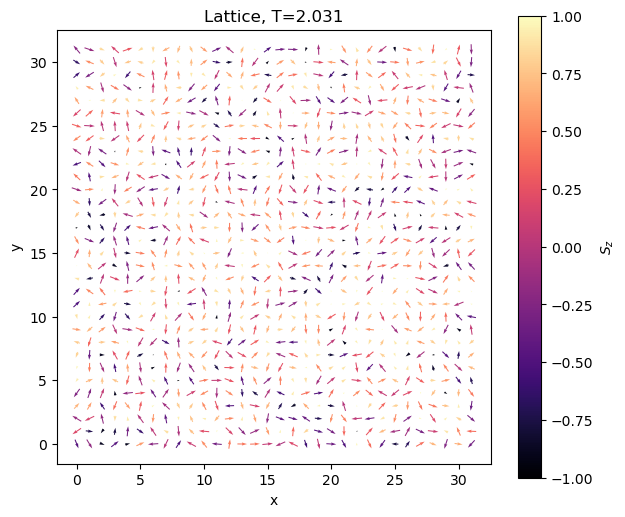

Simulating at T=1.9745


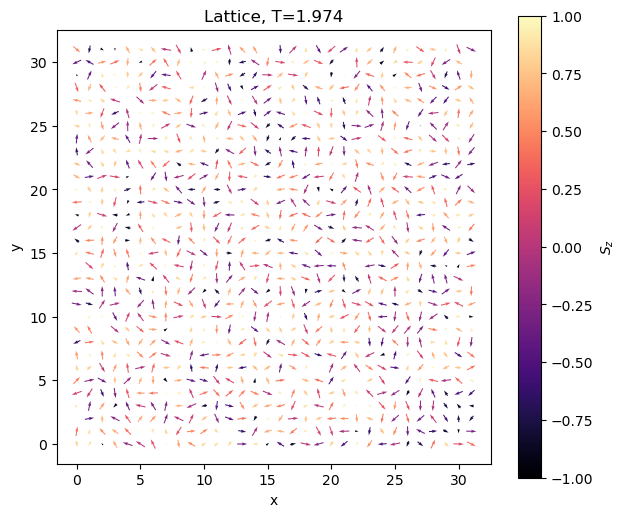

Simulating at T=1.9181


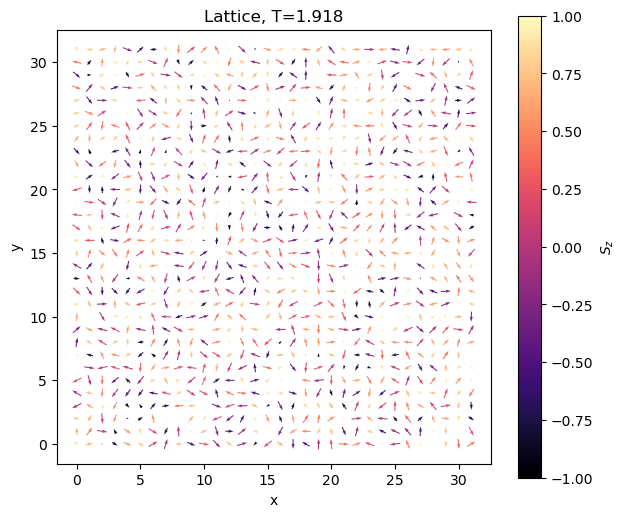

Simulating at T=1.8617


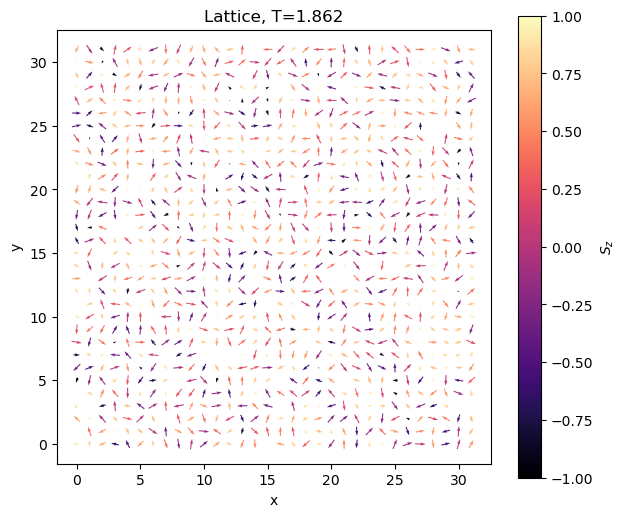

Simulating at T=1.8053


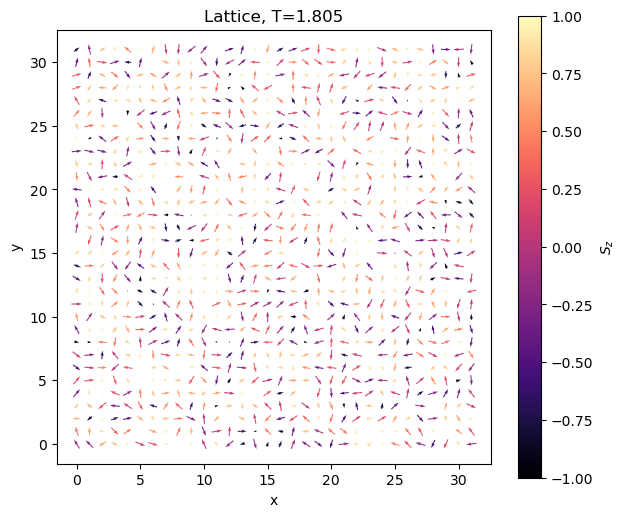

Simulating at T=1.7489


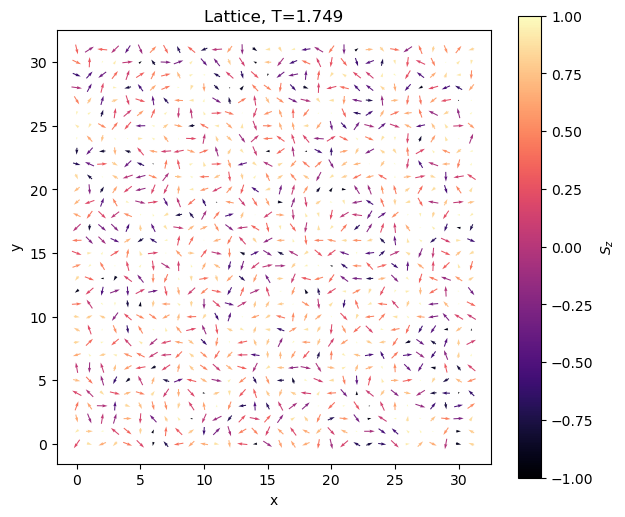

Simulating at T=1.6925


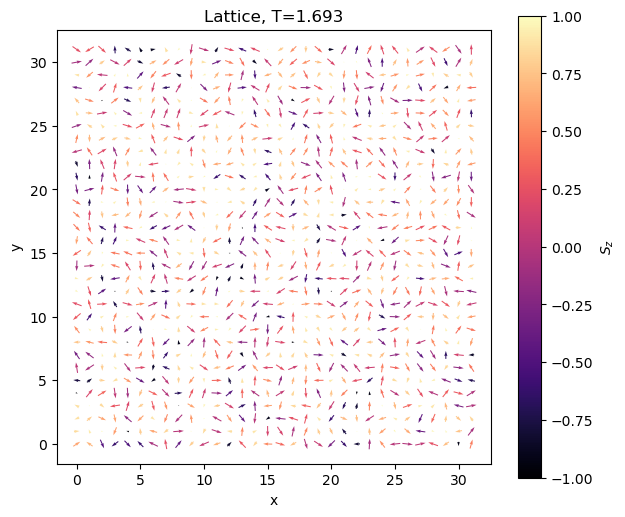

Simulating at T=1.6362


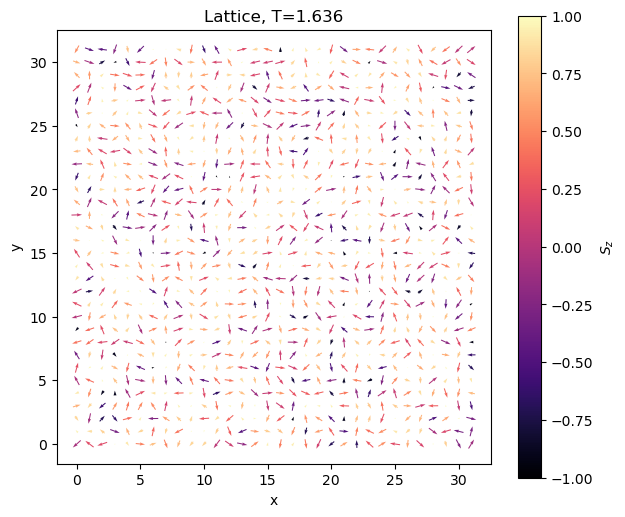

Simulating at T=1.5798


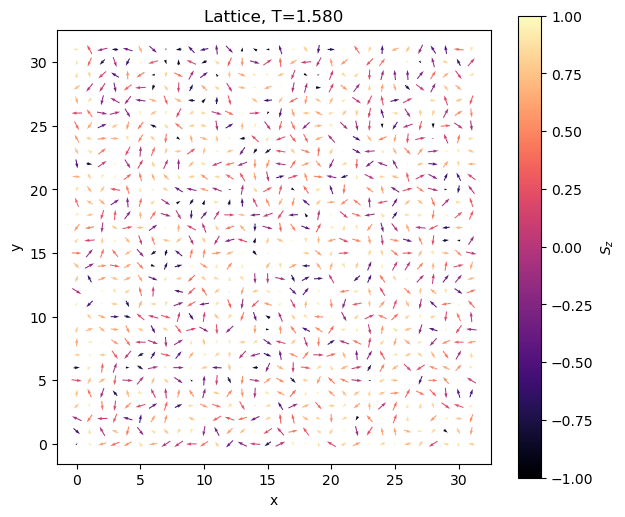

Simulating at T=1.5234


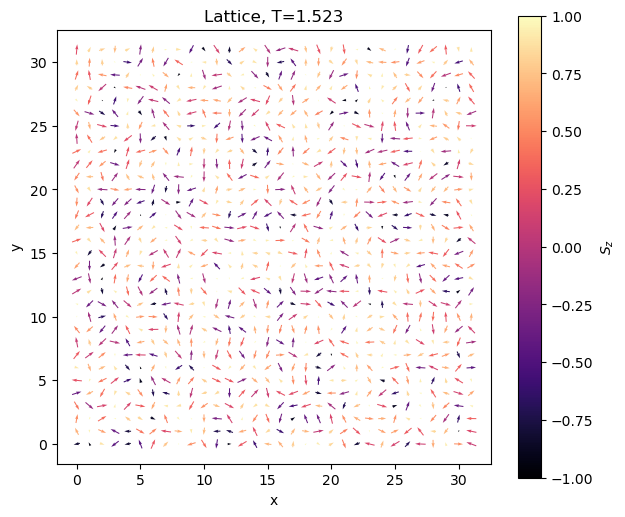

Simulating at T=1.4670


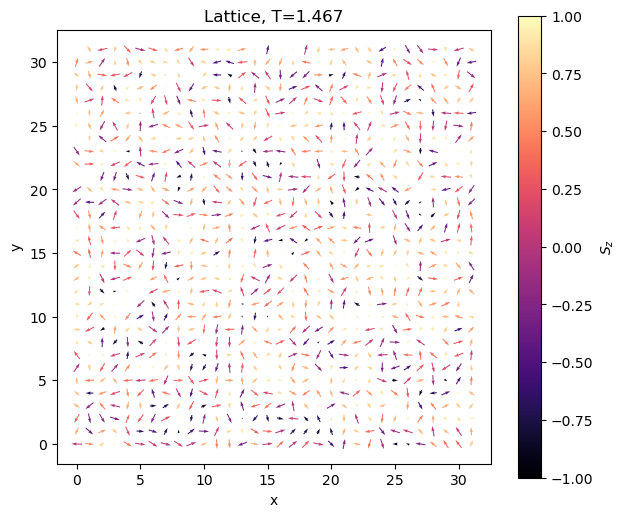

Simulating at T=1.4106


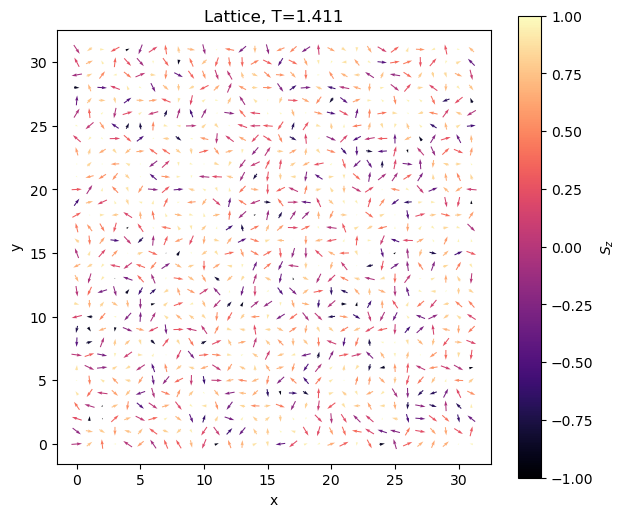

Simulating at T=1.3542


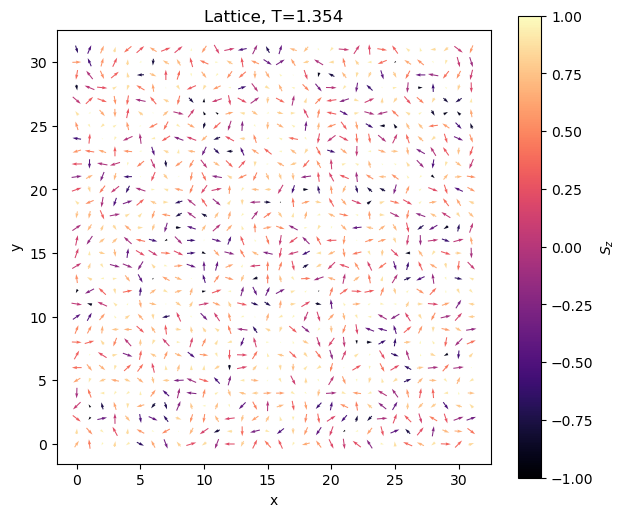

Simulating at T=1.2978


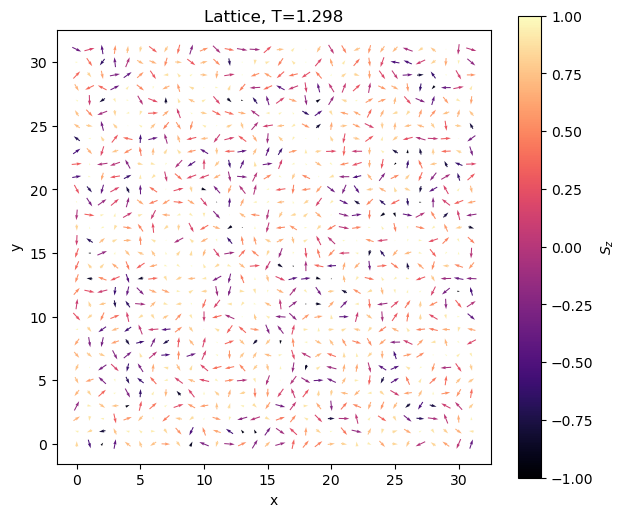

Simulating at T=1.2415


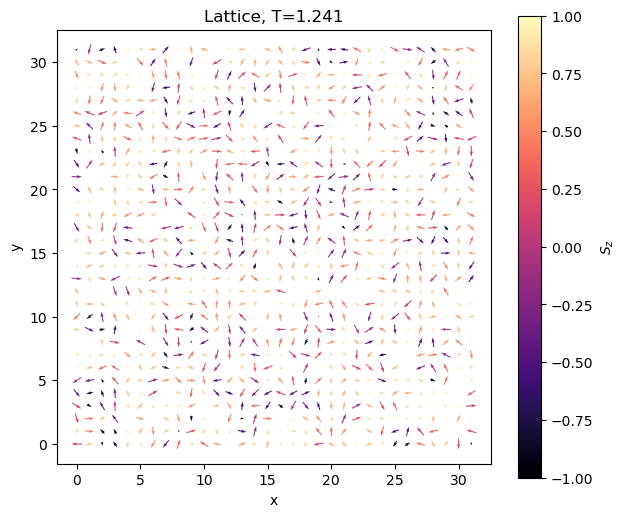

Simulating at T=1.1851


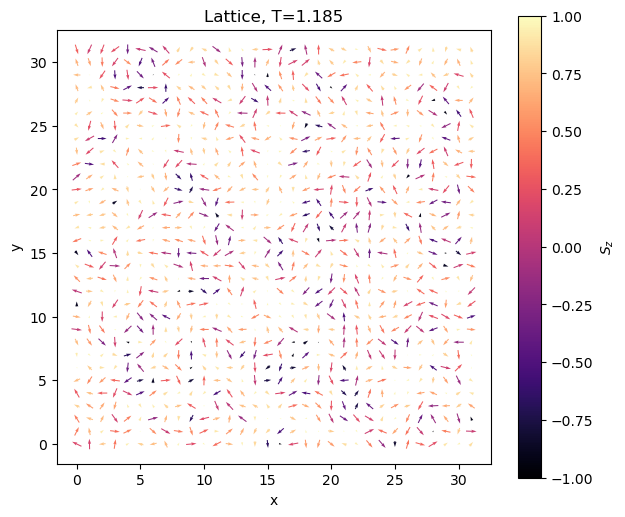

Simulating at T=1.1287


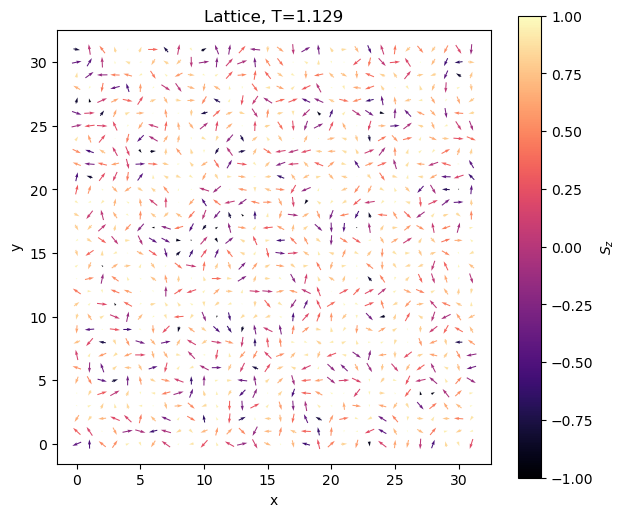

Simulating at T=1.0723


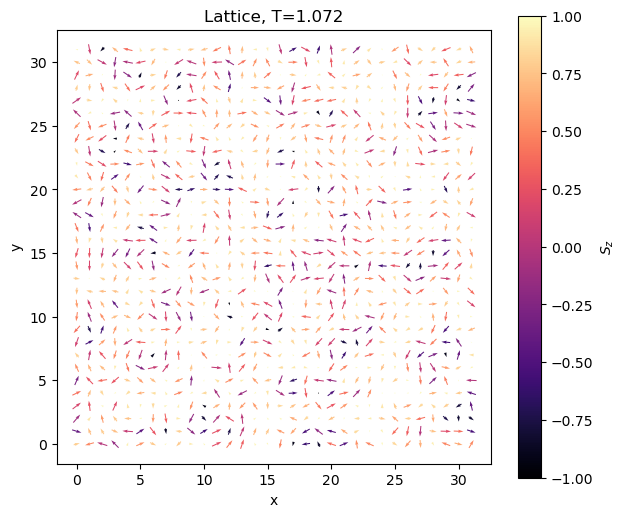

Simulating at T=1.0159


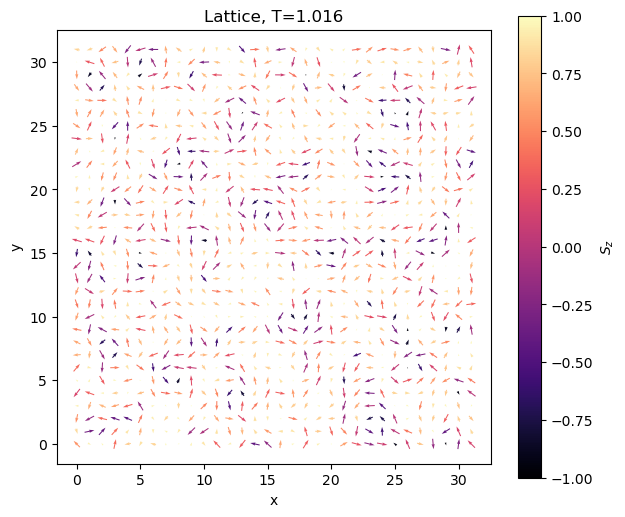

Simulating at T=0.9595


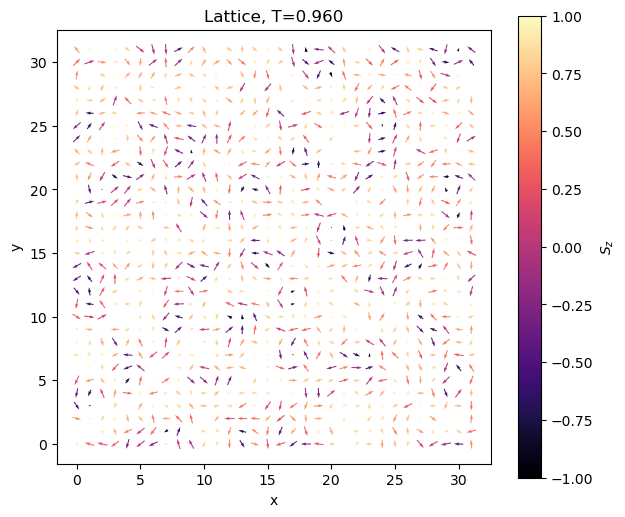

Simulating at T=0.9032


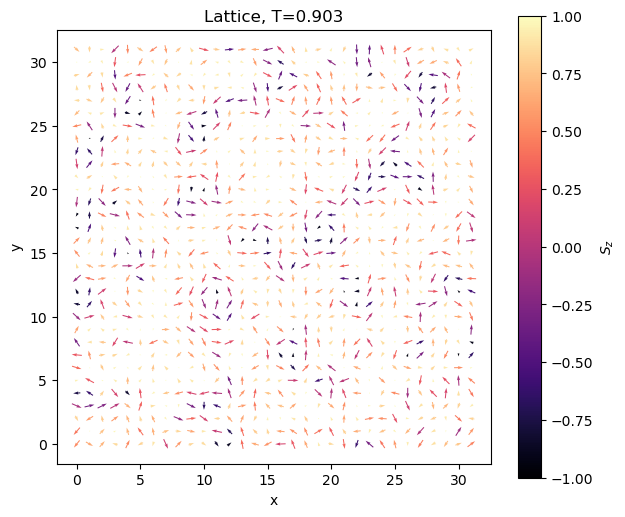

Simulating at T=0.8468


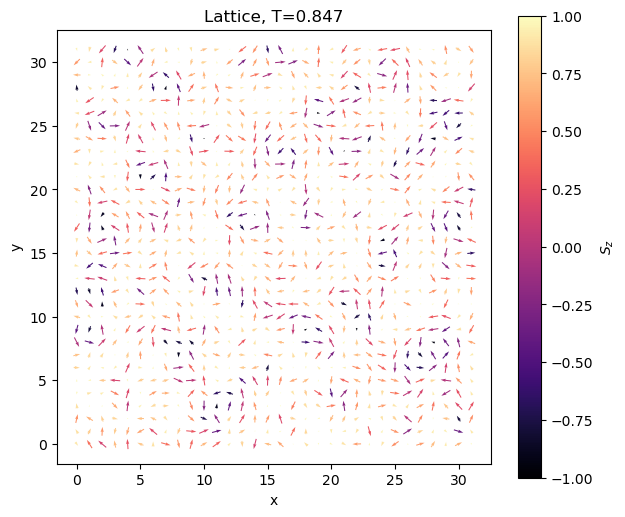

Simulating at T=0.7904


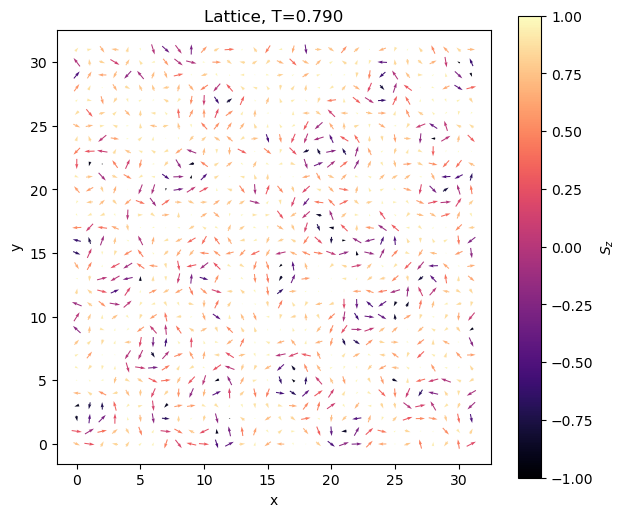

Simulating at T=0.7340


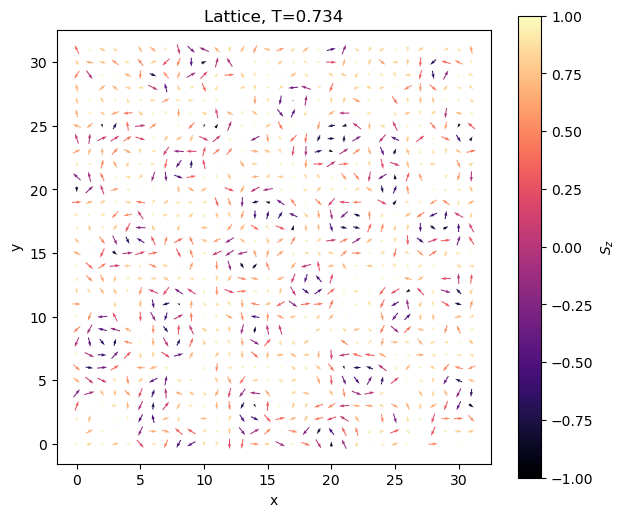

Simulating at T=0.6776


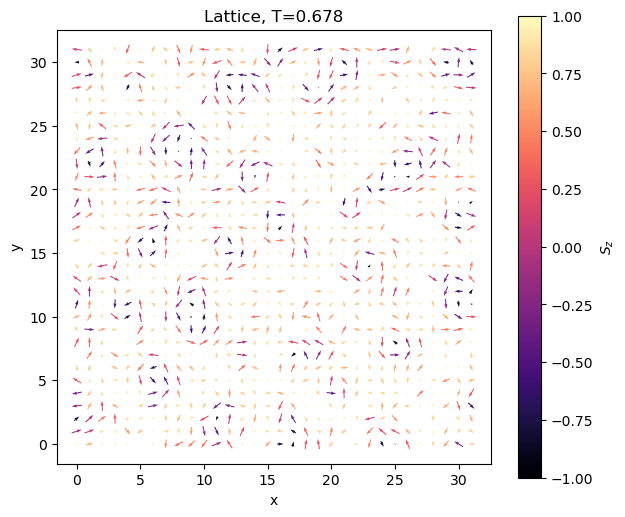

Simulating at T=0.6212


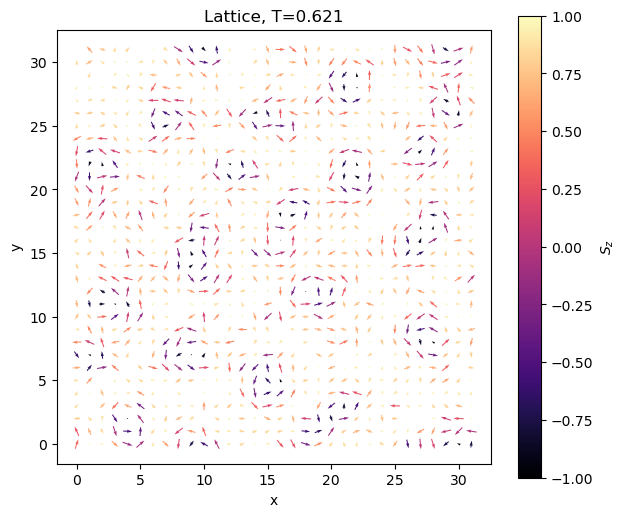

Simulating at T=0.5648


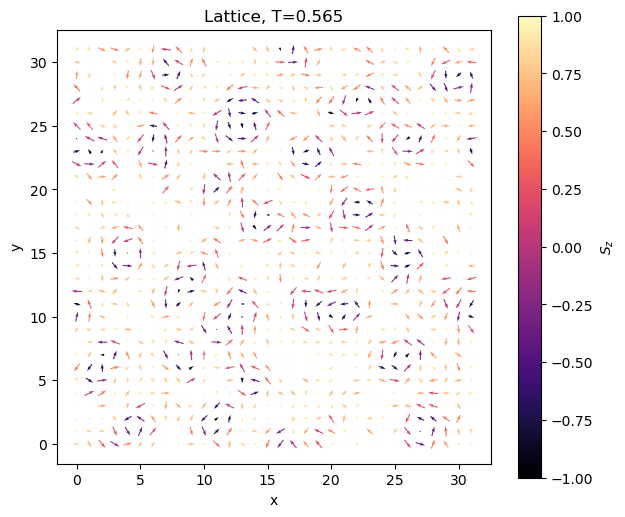

Simulating at T=0.5085


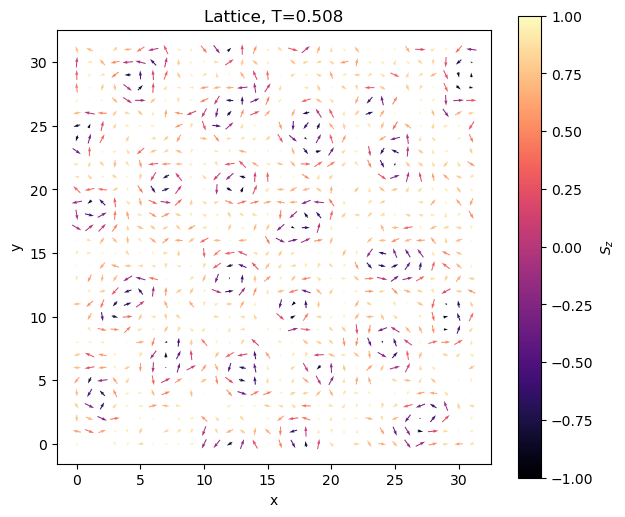

Simulating at T=0.4521


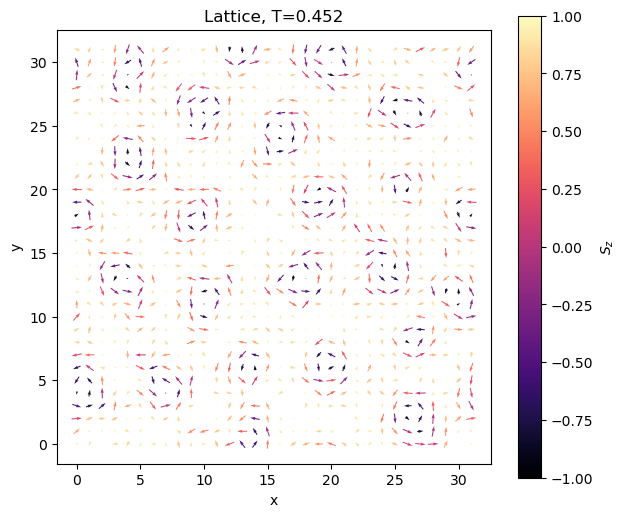

Simulating at T=0.3957


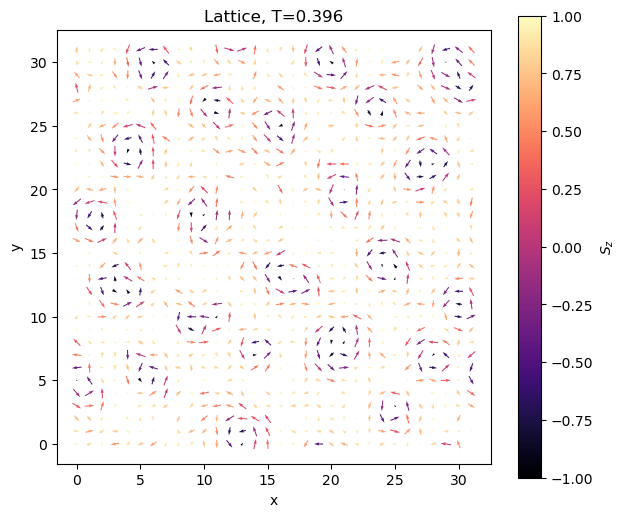

Simulating at T=0.3393


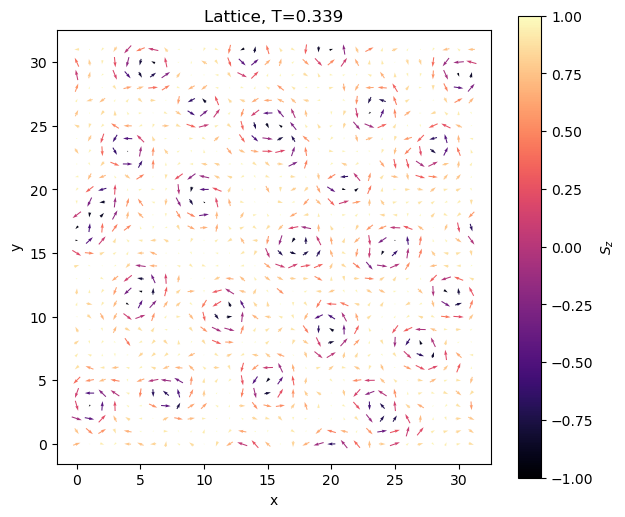

Simulating at T=0.2829


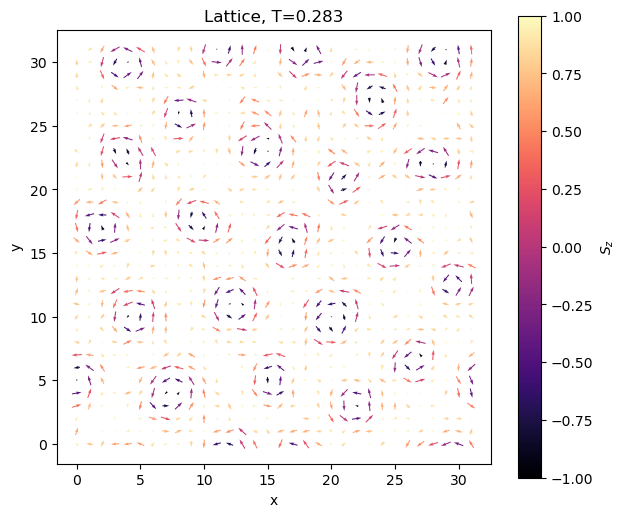

Simulating at T=0.2265


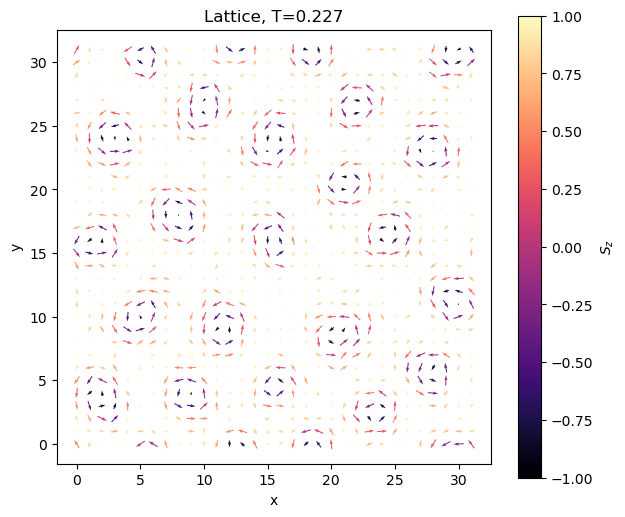

Simulating at T=0.1702


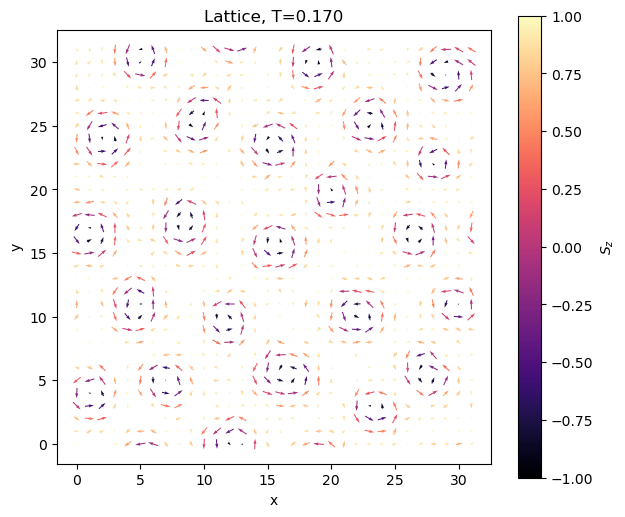

Simulating at T=0.1138


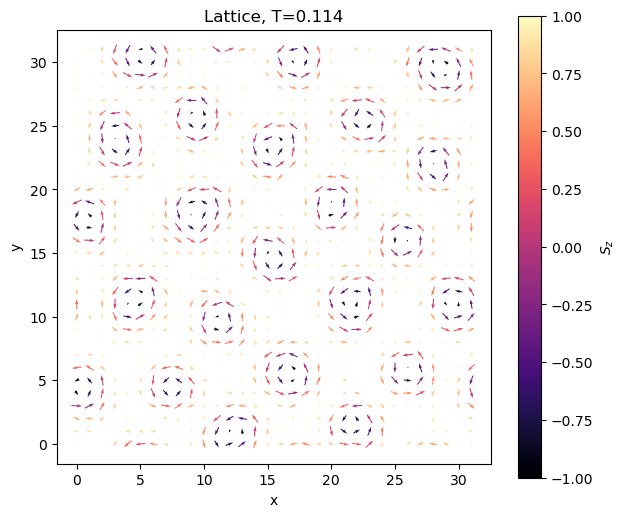

Simulating at T=0.0574


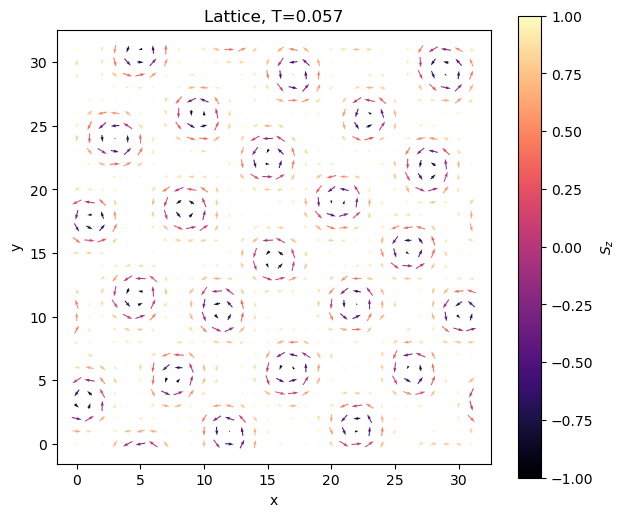

Simulating at T=0.0010


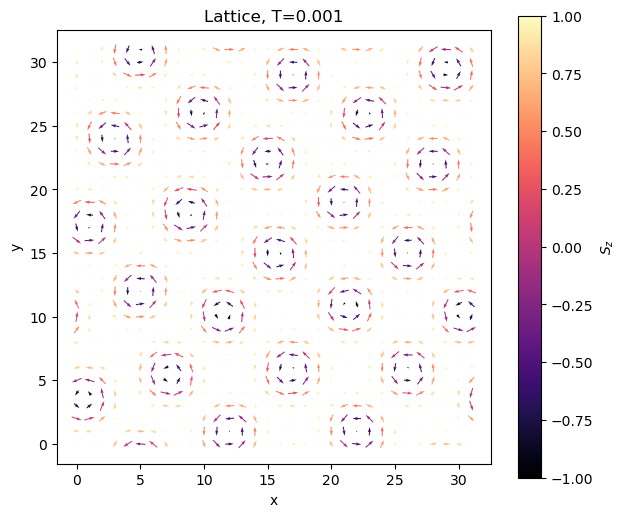

In [ ]:
# final_lattice = lattice.copy()
# for i in T:
#     print(f"Simulating at T={i:.4f}")
#     temp = i
#     simulate(final_lattice, temp, B_z)

#     spins = final_lattice

#     fig, ax = plt.subplots(figsize=(7, 6))
#     q = ax.quiver(
#         spins[:, :, 0].T,
#         spins[:, :, 1].T,
#         spins[:, :, 2].T,
#         cmap="magma",
#         norm=Normalize(vmin=-1, vmax=1),
#         pivot="middle",
#         scale_units="xy",
#         scale=1.2,
#     )
    
#     fig.colorbar(q, ax=ax, label=r"$S_z$")
#     ax.set_xlabel("x")
#     ax.set_ylabel("y")
#     ax.set_aspect("equal")
#     ax.set_title(f"Lattice, T={temp:.3f}")
#     plt.show()